# Laboratorio 9 - ¿Importa cómo partimos los datos?
**Universidad Rafael Landívar · Facultad de Ingeniería**  
**Ciencia de Datos · Sección 2 · Segundo semestre 2026**  
Docente: Ing. Max Cerna

| Integrante (carné) | Rol propuesto | Responsabilidad |
|---|---|---|
| GARCÍA ELÍAS JOSÉ ANDRÉS (1106423) | Quien programa | Escribe y ejecuta el código |
| XIQUIN CUMES OSCAR DANIEL (1118423) | Quien registra | Registra predicciones y resultados |
| RUANO LAM JUAN LUIS DANIEL (1247723) | Quien cuestiona | Pide predicciones y anota desacuerdos |

**Roles:** distribución propuesta en el orden recibido; revisar si corresponde al trabajo de cada integrante.

**Estado:** análisis ejecutado; revisar el razonamiento en grupo antes de entregar.

**Uso de IA.** Se utilizó Codex para leer el enunciado, preparar el código,
proponer hipótesis antes de ejecutar, ejecutar las particiones, comprobar
resultados y redactar un borrador de explicaciones. La IA aportó organización,
reproducibilidad y apoyo para distinguir las situaciones que simula cada evaluación.
Las hipótesis son propuestas con IA y no se atribuyen a una conversación
del trío. El grupo debe revisar y poder explicar todas las respuestas.
No se inventó una conversación con otro grupo.

**Objetivo:** comparar particiones usando el mismo M1 (regresión logística)
y M0 (DummyClassifier). El F1 corresponde a la clase positiva **baja = 1**,
no al promedio macro ni a la exactitud. Cada F1 de M1 se presenta junto a M0.

## Preparación: cargar y reconocer los datos
Se usa una copia sin modificar del CSV de Descargas. No se eliminan
duplicados ni se normalizan categorías en estos experimentos: la guía
prescribe usar esta base y mantener comparabilidad entre grupos.
Los problemas de calidad se documentan como limitaciones.

Las hipótesis iniciales quedaron registradas en HIPOTESIS_PREVIAS.md antes
del primer entrenamiento. Aquí se conservan antes de la celda de cada parte.

In [1]:
import os
import sys
import json
import hashlib
import platform
import tempfile
from pathlib import Path
from importlib.metadata import version

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'lab9-matplotlib'))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

RAIZ = Path.cwd()
RUTA_DATOS = RAIZ / 'data' / 'pedidos_ruta_verde.csv'
if not RUTA_DATOS.exists():
    # Permite ejecutar desde output/ o con el CSV al lado del notebook.
    candidatos = [RAIZ.parent / 'data' / 'pedidos_ruta_verde.csv',
                  RAIZ / 'pedidos_ruta_verde.csv']
    RUTA_DATOS = next((p for p in candidatos if p.exists()), RUTA_DATOS)
if not RUTA_DATOS.exists():
    raise FileNotFoundError('Coloque pedidos_ruta_verde.csv en data/ o junto al notebook.')
if RUTA_DATOS.parent.name == 'data':
    RAIZ = RUTA_DATOS.parent.parent
SALIDA = RAIZ / 'output'
FIGURAS = SALIDA / 'graficas'
FIGURAS.mkdir(parents=True, exist_ok=True)
SEMILLAS = [0, 1, 7, 42, 2026]
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 15)
pd.set_option('display.precision', 4)
pd.set_option('display.max_colwidth', 100)

df = pd.read_csv(RUTA_DATOS, parse_dates=['fecha'])
df.info()
display(df.isna().sum().rename('Nulos').to_frame())
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 626 entries, 0 to 625
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   pedido_id              626 non-null    int64         
 1   fecha                  626 non-null    datetime64[ns]
 2   departamento           626 non-null    object        
 3   municipio              626 non-null    object        
 4   zona                   626 non-null    object        
 5   restaurante            626 non-null    object        
 6   categoria_restaurante  626 non-null    object        
 7   metodo_pago            626 non-null    object        
 8   total_pedido_gtq       626 non-null    float64       
 9   tiempo_entrega_min     626 non-null    float64       
 10  distancia_km           606 non-null    float64       
 11  calificacion           591 non-null    float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(6)
memory usa

,Nulos
pedido_id,0
fecha,0
departamento,0
municipio,0
zona,0
restaurante,0
categoria_restaurante,0
metodo_pago,0
total_pedido_gtq,0
tiempo_entrega_min,0


,pedido_id,fecha,departamento,municipio,zona,restaurante,categoria_restaurante,metodo_pago,total_pedido_gtq,tiempo_entrega_min,distancia_km,calificacion
0,1576,2026-01-03,Guatemala,Guatemala,Zona 1,Café Chuwa,Cafetería,Tarjeta,42.67,19.9,4.27,4.0
1,1453,2026-02-01,Guatemala,Guatemala,Zona 1,Burger Xelajú,Comida rápida,TARJETA,48.75,25.4,1.97,4.0
2,1131,2026-07-08,Guatemala,Mixco,Zona 4 de Mixco,Tacos El Chapín,Comida mexicana,Efectivo,33.51,32.6,NaN,4.0
3,1359,2026-06-21,Guatemala,Villa Nueva,Centro,Café Chuwa,Cafetería,Efectivo,35.00,28.2,4.34,4.0
4,1272,2026-05-28,Guatemala,Guatemala,Zona 15,Burger Xelajú,Comida rápida,Transferencia,56.48,196.0,2.97,4.0


In [2]:
reconocimiento = pd.DataFrame({
    'Dato': ['Filas / pedidos registrados', 'IDs de pedido únicos', 'Restaurantes',
             'Fecha mínima', 'Fecha máxima', 'Entrega mínima (min)',
             'Entrega máxima (min)', 'Duplicados exactos', 'IDs repetidos'],
    'Valor': [len(df), df.pedido_id.nunique(), df.restaurante.nunique(),
              str(df.fecha.min().date()), str(df.fecha.max().date()),
              df.tiempo_entrega_min.min(), df.tiempo_entrega_min.max(),
              int(df.duplicated().sum()), int(df.pedido_id.duplicated().sum())]
})
display(reconocimiento)
display(df.restaurante.value_counts().rename('Pedidos').to_frame())
fuera_reg = df[~((df.tiempo_entrega_min > 0) & (df.tiempo_entrega_min < 200))]
display(fuera_reg[['pedido_id', 'tiempo_entrega_min']])

,Dato,Valor
0,Filas / pedidos registrados,626
1,IDs de pedido únicos,620
2,Restaurantes,7
3,Fecha mínima,2026-01-01
4,Fecha máxima,2026-08-31
5,Entrega mínima (min),-9.5
6,Entrega máxima (min),196.5
7,Duplicados exactos,6
8,IDs repetidos,6


,Pedidos
restaurante,
Tacos El Chapín,98
Burger Xelajú,97
Pollo Real,93
Café Chuwa,91
Pupusas Doña Lupe,91
Sushi Ixchel,85
Pizza Volcán,71


,pedido_id,tiempo_entrega_min
86,1132,-5.8
133,1518,-3.9
148,1530,-3.0
268,1568,-9.5


### Reconocimiento del archivo
Hay **626 filas de pedidos**, correspondientes a **620 IDs
distintos**, de **7 restaurantes**, entre el
**1 de enero y el 31 de agosto de 2026**. La diferencia entre filas e IDs se
debe a **6 duplicados exactos**.

Solo tienen nulos **distancia_km (20)** y
**calificacion (35)**; las otras diez columnas no
tienen nulos. El mínimo de tiempo_entrega_min es **-9.5 minutos**
y el máximo **196.5 minutos**. Hay **4
tiempos no positivos**, que son imposibles como duración de una entrega.
Los tiempos cercanos a 200 minutos son extremos, pero no son imposibles solo
por ser altos. El filtro indicado conserva **622 filas** para reg;
no se aplican recortes adicionales.

Al quitar únicamente calificaciones faltantes quedan **591 pedidos**:
**54 bajas** y **537 no bajas**, con una
tasa de **9.14%**. Los tiempos negativos no se excluyen
de cal porque no son variables de M1 y el enunciado no pide ese filtro para
clasificación. No se imputan las respuestas faltantes.

### Las dos preguntas de negocio
1. Clasificación: ¿este pedido recibirá calificación baja?
2. Regresión: ¿cuántos minutos tardará?

La guía prepara ambas bases, pero sus partes A-F fijan un clasificador y
reportan F1. Por ello, se prepara reg tal como indica el enunciado y se
responde la pregunta de disponibilidad de columnas; no se inventa un modelo
de regresión ni un MAE que la guía no solicita.

In [3]:
# Pregunta 1 (clasificación): ¿este pedido recibirá calificación baja?
cal = df.dropna(subset=['calificacion']).copy()
cal['baja'] = (cal['calificacion'] <= 2).astype(int)
print(cal['baja'].mean())

# Pregunta 2 (regresión): ¿cuántos minutos tardará el pedido?
reg = df[(df.tiempo_entrega_min > 0) & (df.tiempo_entrega_min < 200)].copy()
print(f'Clasificación: {len(cal)} filas, {int(cal.baja.sum())} positivos, '
      f'{100 * cal.baja.mean():.2f}% de calificación baja.')
print(f'Regresión: {len(reg)} filas; se excluyen {len(df) - len(reg)} tiempos por el filtro.')

0.09137055837563451
Clasificación: 591 filas, 54 positivos, 9.14% de calificación baja.
Regresión: 622 filas; se excluyen 4 tiempos por el filtro.


### Pregunta 1. ¿Qué columnas no pueden usarse al ingresar el pedido?
| Columna | ¿Existe cuando entra el pedido? | Decisión y justificación |
|---|---|---|
| pedido_id | Sí, como identificador | No usar como señal de calidad: identifica una fila, no explica la entrega |
| fecha | Sí, fecha/hora de creación | Puede usarse si representa la creación, no la fecha final de entrega |
| departamento | Sí, del destino | Disponible si el destino ya está registrado |
| municipio | Sí, del destino | Disponible al registrar la dirección |
| zona | Sí, del destino | Disponible al registrar la dirección |
| restaurante | Sí | El negocio seleccionado ya se conoce |
| categoria_restaurante | Sí, del catálogo | Disponible para restaurantes registrados |
| metodo_pago | Sí, si se elige al ordenar | Revisar que no sea el método final corregido después |
| total_pedido_gtq | Sí, monto inicial | Usar el monto cotizado al ordenar, no un monto corregido después |
| tiempo_entrega_min | **No** | Es el resultado futuro que queremos predecir; usarlo revelaría la respuesta |
| distancia_km | Depende de cómo se mida | Una distancia estimada con direcciones conocidas sí; kilómetros realmente recorridos, no |
| calificacion | **No** | El cliente califica después de recibir el pedido |
| baja (derivada) | **No** | Se deriva de calificacion; es la respuesta del clasificador |

Las exclusiones inequívocas para anticipar minutos son tiempo_entrega_min
y calificacion; baja tampoco sería un insumo. La disponibilidad se decide
por el momento de captura del dato, no solo por su nombre. El laboratorio
no describe el origen exacto de distancia_km; esa disponibilidad requiere
confirmación para producción. Para A-D se conservan las cinco variables
que el docente fijó.

## Definición del modelo
Se copian los bloques M1 y M0 del enunciado sin cambiar parámetros ni variables.
Cada evaluación crea un modelo nuevo. La mediana, la escala y las categorías
se aprenden al llamar fit con el train, dentro del Pipeline.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, recall_score

NUM = ['distancia_km', 'total_pedido_gtq']
CAT = ['zona', 'categoria_restaurante', 'metodo_pago']
FEATURES = NUM + CAT

def nuevo_modelo():
    """M1. Siempre se crea nuevo; nunca se reutiliza uno ya entrenado."""
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('esc', StandardScaler())]), NUM),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ])
    return Pipeline([
        ('prep', prep),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
    ])

def entrenar_y_medir(train, test, target='baja'):
    """Entrena M1 con 'train', mide en 'test' y devuelve F1 y recall."""
    m = nuevo_modelo()
    m.fit(train[FEATURES], train[target])
    pred = m.predict(test[FEATURES])
    return {'f1': f1_score(test[target], pred),
            'recall': recall_score(test[target], pred),
            'n_test': len(test),
            'positivos_test': int(test[target].sum())}

In [5]:
def medir_baseline(train, test, target='baja'):
    """M0: modelo "tonto". Predice siempre la clase más común."""
    d = DummyClassifier(strategy='most_frequent')
    d.fit(train[FEATURES], train[target])
    return f1_score(test[target], d.predict(test[FEATURES]))

### Pregunta 2. Predicción previa del F1 de M0
**Hipótesis previa:** F1 = 0 si la clase mayoritaria del train es "no baja".
Al responder siempre 0, M0 no encuentra verdaderos positivos de la clase 1.
Tener muchos aciertos de la clase mayoritaria no implica un buen F1 para
detectar las calificaciones bajas. La condición de mayoría se comprueba
para cada partición, en lugar de asumirla sin verificar.

In [6]:
# Solo organiza tablas; no cambia los modelos ni las particiones.
def tabla_semillas(resultados):
    tabla = resultados[['semilla', 'n_test', 'positivos_test', 'pct_positivos',
                        'f1', 'f1_baseline', 'recall']].copy()
    tabla.columns = ['Semilla', 'Pedidos test', 'Positivos test', '% positivos',
                     'F1 M1', 'F1 M0', 'Recall M1']
    minimo = {c: tabla[c].min() for c in tabla.columns if c != 'Semilla'}
    maximo = {c: tabla[c].max() for c in tabla.columns if c != 'Semilla'}
    rango = {'Semilla': 'mín - máx', **{
        c: f'{minimo[c]:.4f} - {maximo[c]:.4f}' if c in ['F1 M1', 'F1 M0', 'Recall M1']
        else f'{minimo[c]:.2f} - {maximo[c]:.2f}'
        for c in minimo}}
    return pd.concat([tabla, pd.DataFrame([rango])], ignore_index=True)

def comprobar_particion(train, test):
    assert len(train) > 0 and len(test) > 0
    assert set(train.index).isdisjoint(test.index)
    assert len(train) + len(test) == len(cal)
    assert train.baja.nunique() == 2 and test.baja.nunique() == 2
    assert train.baja.mean() < 0.5, 'M0 ya no respondería siempre no baja.'

registros_splits = []
def registrar_split(nombre, train, test):
    # Se registra el índice original de cada fila para auditar las particiones.
    registros_splits.extend({'experimento': nombre, 'fila_csv': int(i),
                             'pedido_id': int(cal.loc[i, 'pedido_id']), 'conjunto': conjunto}
                            for conjunto, bloque in [('train', train), ('test', test)]
                            for i in bloque.index)

## Parte A. Cinco resultados con la misma base
**Predicción previa:** los F1 serán parecidos, pero no idénticos. Las semillas
cambian los pedidos de train/test y el número y la dificultad de los positivos.
No esperamos que cambiar la semilla mejore por sí mismo el algoritmo.

In [7]:
from sklearn.model_selection import train_test_split

filas = []
for semilla in [0, 1, 7, 42, 2026]:
    train, test = train_test_split(cal, test_size=0.2, random_state=semilla)
    comprobar_particion(train, test)
    r = entrenar_y_medir(train, test)
    r['semilla'] = semilla
    r['f1_baseline'] = medir_baseline(train, test)
    r['pct_positivos'] = 100 * test.baja.mean()
    filas.append(r)
    registrar_split(f'A_{semilla}', train, test)

resultados_a = pd.DataFrame(filas)
display(tabla_semillas(resultados_a))
resultados_a.to_csv(SALIDA / 'parte_A_aleatorio.csv', index=False)

,Semilla,Pedidos test,Positivos test,% positivos,F1 M1,F1 M0,Recall M1
0,0,119,15,12.605,0.2264,0.0,0.4
1,1,119,12,10.084,0.2456,0.0,0.5833
2,7,119,11,9.2437,0.1132,0.0,0.2727
3,42,119,14,11.7647,0.1667,0.0,0.3571
4,2026,119,3,2.521,0.0952,0.0,0.6667
5,mín - máx,119.00 - 119.00,3.00 - 15.00,2.52 - 12.61,0.0952 - 0.2456,0.0000 - 0.0000,0.2727 - 0.6667


### Resultado frente a la predicción
El F1 varió de **0.0952** (semilla 2026) a
**0.2456** (semilla 1), frente a **M0 = 0.0000**
en todas las semillas. Acertamos en que no serían idénticos, pero la expectativa
de resultados "parecidos" fue demasiado optimista: la amplitud es considerable
para un modelo de desempeño bajo.

### Pregunta 3. Diferencia entre mejor y peor F1
La diferencia es **0.1504**, equivalente a **15.04 puntos**
si expresamos F1 en una escala de 0 a 100. El mejor resultado supera en más
del doble al peor. Es una diferencia grande para escoger un número de
desempeño con una única partición.

### Pregunta 4. Otro grupo obtiene un F1 diferente: ¿quién tiene razón?
Ambos resultados pueden ser correctos si usan distintas semillas y reproducen
el mismo procedimiento. Si usan las mismas filas, semilla y versiones deberían
coincidir; si no, habría que revisar limpieza, orden de filas, variables y
ejecución. No realizamos aquí una conversación con otro grupo; esa parte de
la actividad debe hacerse en clase.

Para describir la sensibilidad al reparto aleatorio reportaríamos el promedio
**M1 = 0.1694; M0 = 0.0000**, acompañado del
rango observado **M1 = 0.0952-0.2456; M0 = 0.0000**,
las cinco semillas y el tamaño de test. No elegiríamos la mejor semilla
para anunciar desempeño. Este promedio es una descripción de estas cinco
particiones; no constituye una garantía ni un intervalo de confianza.
Para pedidos futuros escogeríamos otra evaluación, la temporal de C.

### Pregunta 5. Relación entre positivos de test y F1
Cada test contiene 119 pedidos, pero en A hay entre **3
y 15 positivos**, es decir, entre
**2.52% y 12.61%**. Con pocos
positivos, un acierto o un error cambia mucho el resultado. La semilla 2026
contiene solo 3 positivos y da **M1 = 0.0952; M0 = 0.0000**, aunque su recall
es 0.6667: encontrar dos de tres casos no evita penalizar falsas alarmas.

En estas cinco observaciones hay asociación positiva descriptiva
(correlación ≈ 0.70), pero no una regla de que
"más positivos siempre produce mayor F1": la semilla 0 tiene 15 positivos y
la 1 tiene 12, y la 1 obtiene mayor F1. El resultado también depende de
verdaderos positivos, falsos positivos, falsos negativos y de los pedidos
que quedaron en train.

## Parte B. Forzar la proporción
**Predicción previa:** stratify estabilizará la proporción de positivos.
Puede reducir la dispersión de F1, pero no garantiza elevar su promedio ni
eliminar diferencias de dificultad entre pedidos.

,Semilla,Pedidos test,Positivos test,% positivos,F1 M1,F1 M0,Recall M1
0,0,119,11,9.2437,0.1455,0.0,0.3636
1,1,119,11,9.2437,0.2128,0.0,0.4545
2,7,119,11,9.2437,0.1562,0.0,0.4545
3,42,119,11,9.2437,0.2295,0.0,0.6364
4,2026,119,11,9.2437,0.1404,0.0,0.3636
5,mín - máx,119.00 - 119.00,11.00 - 11.00,9.24 - 9.24,0.1404 - 0.2295,0.0000 - 0.0000,0.3636 - 0.6364


,Partición,F1 promedio M1,F1 promedio M0,F1 mínimo M1,F1 máximo M1,Rango F1 M1,Desv. F1 M1 (muestral),% positivos mínimo,% positivos máximo
0,A: aleatorio,0.1694,0.0,0.0952,0.2456,0.1504,0.0666,2.5210,12.6050
1,B: estratificado,0.1769,0.0,0.1404,0.2295,0.0892,0.0412,9.2437,9.2437


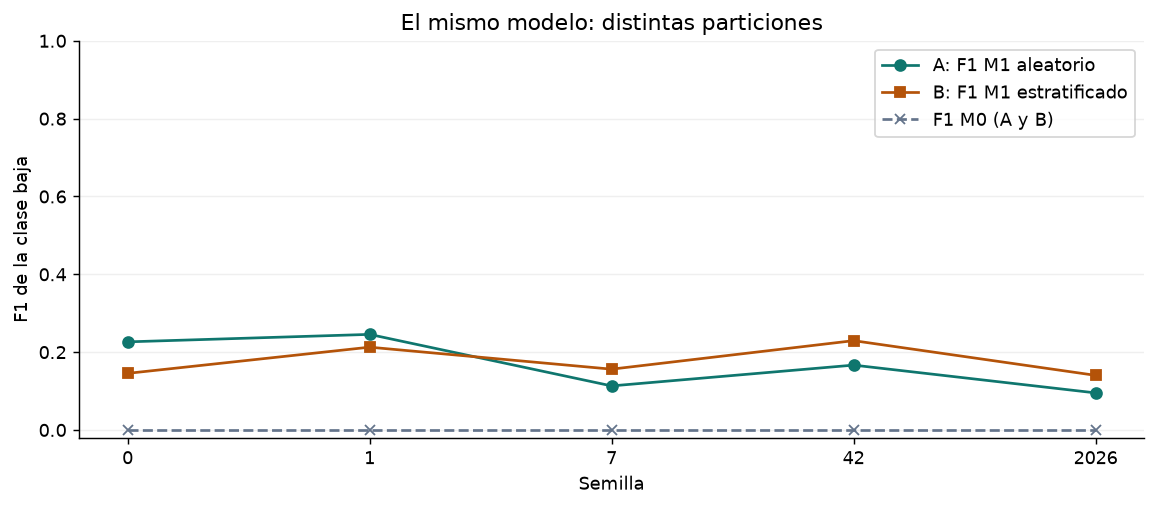

In [8]:
filas = []
for semilla in SEMILLAS:
    train, test = train_test_split(cal, test_size=0.2, random_state=semilla,
                                   stratify=cal['baja'])
    comprobar_particion(train, test)
    r = entrenar_y_medir(train, test)
    r['semilla'] = semilla
    r['f1_baseline'] = medir_baseline(train, test)
    r['pct_positivos'] = 100 * test.baja.mean()
    filas.append(r)
    registrar_split(f'B_{semilla}', train, test)

resultados_b = pd.DataFrame(filas)
display(tabla_semillas(resultados_b))
resumen_ab = pd.DataFrame([
    {'Partición': nombre, 'F1 promedio M1': res.f1.mean(),
     'F1 promedio M0': res.f1_baseline.mean(), 'F1 mínimo M1': res.f1.min(),
     'F1 máximo M1': res.f1.max(), 'Rango F1 M1': res.f1.max() - res.f1.min(),
     'Desv. F1 M1 (muestral)': res.f1.std(ddof=1),
     '% positivos mínimo': res.pct_positivos.min(),
     '% positivos máximo': res.pct_positivos.max()}
    for nombre, res in [('A: aleatorio', resultados_a), ('B: estratificado', resultados_b)]
])
display(resumen_ab)
resultados_b.to_csv(SALIDA / 'parte_B_estratificado.csv', index=False)
resumen_ab.to_csv(SALIDA / 'resumen_A_B.csv', index=False)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(SEMILLAS))
ax.plot(x, resultados_a.f1, 'o-', label='A: F1 M1 aleatorio', color='#0f766e')
ax.plot(x, resultados_b.f1, 's-', label='B: F1 M1 estratificado', color='#b45309')
ax.plot(x, resultados_a.f1_baseline, 'x--', color='#64748b',
        label='F1 M0 (A y B)')
ax.set(xticks=x, xticklabels=SEMILLAS, xlabel='Semilla', ylabel='F1 de la clase baja',
       title='El mismo modelo: distintas particiones', ylim=(-0.02, 1))
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURAS / '01_semillas.png', bbox_inches='tight')
plt.show()

### Pregunta 6. ¿Cambió el promedio, la diferencia entre semillas o ambos?
**Ambos.** El promedio pasa de **M1 = 0.1694; M0 = 0.0000** en A
a **M1 = 0.1769; M0 = 0.0000** en B, un aumento pequeño de
**0.0074** en F1. La amplitud entre semillas disminuye
de **0.1504** a **0.0892**, y la desviación muestral pasa de
**0.0666** a **0.0412**.

La predicción previa se cumple: B conserva **11 positivos en los 119 pedidos
de cada test (9.24%)**, mientras A varía de 3 a 15. El 9.24% es cercano al
9.14% global; las cantidades enteras impiden una igualdad exacta. Aunque la
dispersión baja, no desaparece.

### Pregunta 7. ¿Stratify hace que el modelo prediga mejor?
Stratify cambia el reparto para conservar aproximadamente la proporción de
clases en train y test. No agrega información, cambia el algoritmo ni garantiza
subir F1. Ayuda a que una comparación no dependa tanto de haber reservado muy
pocos positivos. En esta ejecución el promedio subió ligeramente, pero ese
resultado no es una garantía del método. Tampoco corrige por sí solo el orden
temporal, los restaurantes compartidos o los duplicados.

### Pregunta 8. ¿Dónde sería indispensable y dónde importaría menos?
Es especialmente necesario en clasificación con una clase muy rara, por
ejemplo fraude, fallas o calificaciones bajas, si un reparto al azar podría
dejar un test sin casos de interés. Requiere suficientes ejemplos de cada
clase; no crea positivos que no existen.

En un conjunto grande, equilibrado y sin dependencias temporales o por grupo,
la diferencia puede ser pequeña porque el azar ya conserva proporciones
parecidas. En regresión no existen clases naturales para estratificar.
Si el uso es temporal o en grupos nuevos, esa estructura determina la
partición, aunque las proporciones resulten distintas.

## Parte C. Separar por fecha
### 1. Comportamiento mes a mes
La tasa se calcula sobre pedidos con calificación observada. Se muestra
también el número de pedidos sin calificación, para distinguir la tasa
observada de una tasa desconocida sobre todos los pedidos.

,pedidos_totales,pedidos_calificados,sin_calificacion,bajas,pct_bajas
fecha,,,,,
2026-01,76,70,6,5,7.1429
2026-02,87,81,6,8,9.8765
2026-03,83,79,4,8,10.1266
2026-04,80,77,3,6,7.7922
2026-05,63,60,3,4,6.6667
2026-06,78,75,3,9,12.0000
2026-07,83,76,7,1,1.3158
2026-08,76,73,3,13,17.8082


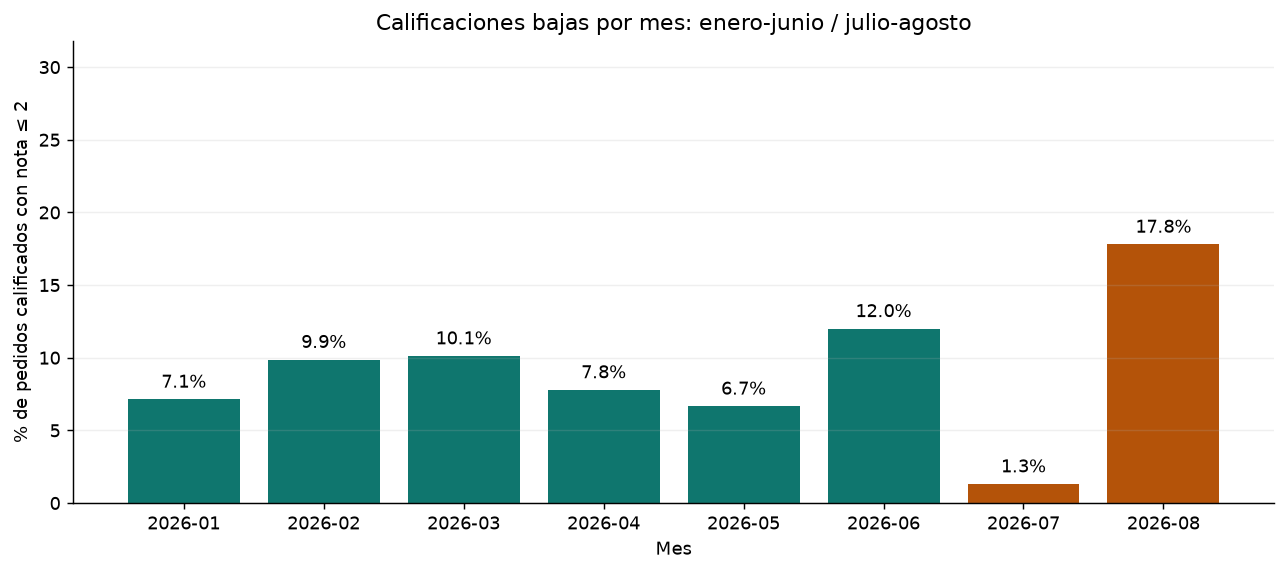

In [9]:
mensual = cal.groupby(cal.fecha.dt.to_period('M')).baja.agg(
    pedidos_calificados='size', bajas='sum', proporcion='mean')
mensual['pct_bajas'] = 100 * mensual.proporcion
totales_mes = df.groupby(df.fecha.dt.to_period('M')).size()
mensual['pedidos_totales'] = totales_mes
mensual['sin_calificacion'] = mensual.pedidos_totales - mensual.pedidos_calificados
display(mensual[['pedidos_totales', 'pedidos_calificados', 'sin_calificacion',
                 'bajas', 'pct_bajas']])
mensual.to_csv(SALIDA / 'prevalencia_mensual.csv')

fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ['#0f766e' if str(m) < '2026-07' else '#b45309' for m in mensual.index]
barras = ax.bar(mensual.index.astype(str), mensual.pct_bajas, color=colores)
ax.bar_label(barras, labels=[f'{v:.1f}%' for v in mensual.pct_bajas], padding=4)
ax.set(xlabel='Mes', ylabel='% de pedidos calificados con nota ≤ 2',
       title='Calificaciones bajas por mes: enero-junio / julio-agosto',
       ylim=(0, min(100, mensual.pct_bajas.max() + 14)))
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURAS / '02_prevalencia_mensual.png', bbox_inches='tight')
plt.show()

### 2. Entrenar con el pasado y probar con el futuro
**Predicción previa, conservada:** esperamos peor F1 que con el split
aleatorio si el servicio cambia en los últimos meses. Esta hipótesis se
registró antes de medir incluso la prevalencia mensual; no se corrige después
de mirar la gráfica. El resultado decidirá si se cumple.

In [10]:
train_t = cal[cal.fecha < '2026-07-01']
test_t = cal[cal.fecha >= '2026-07-01']
comprobar_particion(train_t, test_t)
assert train_t.fecha.max() < test_t.fecha.min()
r_t = entrenar_y_medir(train_t, test_t)
r_t['f1_baseline'] = medir_baseline(train_t, test_t)
registrar_split('C_temporal', train_t, test_t)
display(pd.DataFrame([{'Conjunto': nombre, 'Pedidos': len(bloque),
                       'Desde': bloque.fecha.min().date(), 'Hasta': bloque.fecha.max().date(),
                       'Positivos': int(bloque.baja.sum()), '% positivos': 100* bloque.baja.mean()}
                      for nombre, bloque in [('train', train_t), ('test', test_t)]]))
display(pd.DataFrame([r_t]).rename(columns={'f1': 'F1 M1', 'f1_baseline': 'F1 M0'}))

# Diagnóstico adicional: mismo M1 y misma partición; explica de dónde sale el F1.
from sklearn.metrics import confusion_matrix, precision_score
m_t = nuevo_modelo()
m_t.fit(train_t[FEATURES], train_t.baja)
pred_t = m_t.predict(test_t[FEATURES])
tn, fp, fn, tp = confusion_matrix(test_t.baja, pred_t, labels=[0, 1]).ravel()
diagnostico_t = {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
                'precision': float(precision_score(test_t.baja, pred_t))}
display(pd.DataFrame([diagnostico_t]))
assert np.isclose(f1_score(test_t.baja, pred_t), r_t['f1'])

,Conjunto,Pedidos,Desde,Hasta,Positivos,% positivos
0,train,442,2026-01-01,2026-06-30,40,9.0498
1,test,149,2026-07-02,2026-08-31,14,9.3960


,F1 M1,recall,n_test,positivos_test,F1 M0
0,0.037,0.0714,149,14,0.0


,TN,FP,FN,TP,precision
0,96,39,13,1,0.025


### Pregunta 9. ¿Acertó la predicción y cómo se explica el resultado?
Sí: con fecha se obtuvo **M1 = 0.0370; M0 = 0.0000**,
inferior a los promedios aleatorio y estratificado. Se entrenó con
**442 pedidos de enero-junio** y se probó con **149
pedidos de julio-agosto**, de los cuales **14** son positivos.

La gráfica no muestra una subida gradual: julio tiene **1 baja de 76
calificados (1.32%)** y agosto **13 de 73 (17.81%)**. La tasa conjunta de
train es **9.05%** y la de test
**9.40%**, bastante parecidas. Por tanto, no basta
con decir que "hay más bajas": la composición de pedidos y su relación con
las variables pueden ser diferentes.

En test, M1 encuentra **1 de las 14 bajas**, pierde **13** y genera
**39 falsas alarmas**: recall **0.0714** y precisión **0.0250**.
Esto explica directamente el F1 bajo. El corte revela una transferencia
temporal pobre en esta muestra. Un cambio en el servicio o en los patrones
es una explicación plausible, pero este único corte no prueba su causa;
también intervienen tamaño, selección y dificultad de los pedidos.

### Pregunta 10. ¿Qué medición se parece al uso en septiembre?
La **temporal**, porque entrena con pedidos anteriores y evalúa pedidos
posteriores. No permite aprender de agosto para evaluar febrero. Para el gerente
reportaríamos el resultado de C como evidencia histórica relevante para
el uso futuro, indicando sus tamaños y su bajo recall. No lo presentaríamos
como un F1 ya medido en septiembre, porque el archivo termina en agosto.

### Pregunta 11. ¿Qué tiene de raro entrenar con agosto y probar febrero?
En febrero todavía no existían los pedidos de agosto. Una evaluación así
permite que el modelo aprenda del futuro de los casos evaluados, y responde a
una situación distinta de la operación real. El split aleatorio puede servir
para comparar modelos sobre la población actual, pero no mide fielmente
el reto de anticipar el siguiente periodo.

## Parte D. Separar por restaurante
### 1. Restaurantes presentes a ambos lados de un split aleatorio
Se usa la semilla 42 de A para contar grupos compartidos y pedidos
repetidos entre train/test, conservando las filas originales.

In [11]:
train_a42, test_a42 = train_test_split(cal, test_size=0.2, random_state=42)
compartidos = sorted(set(train_a42.restaurante) & set(test_a42.restaurante))
ids_compartidos = sorted(set(train_a42.pedido_id) & set(test_a42.pedido_id))
print('Restaurantes de test presentes en train:', len(compartidos),
      'de', test_a42.restaurante.nunique())
print(compartidos)
print('IDs de pedido presentes a ambos lados:', len(ids_compartidos))
print('Categorías por restaurante (pueden actuar como señales indirectas del grupo):')
display(cal.groupby('restaurante').categoria_restaurante.unique().to_frame())

Restaurantes de test presentes en train: 7 de 7
['Burger Xelajú', 'Café Chuwa', 'Pizza Volcán', 'Pollo Real', 'Pupusas Doña Lupe', 'Sushi Ixchel', 'Tacos El Chapín']
IDs de pedido presentes a ambos lados: 2
Categorías por restaurante (pueden actuar como señales indirectas del grupo):


,categoria_restaurante
restaurante,
Burger Xelajú,[Comida rápida]
Café Chuwa,[Cafetería]
Pizza Volcán,[Pizzería]
Pollo Real,[Comida rápida]
Pupusas Doña Lupe,[Comida típica]
Sushi Ixchel,[Comida asiática]
Tacos El Chapín,[Comida mexicana]


### 2. Dejar dos restaurantes completos fuera
**Predicción previa:** esperamos peor F1 al probar solo en dos restaurantes
nunca vistos. Aunque restaurante no sea una variable de FEATURES, los
pedidos del mismo negocio pueden compartir categoría, zona y patrones.

In [12]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=2/7, random_state=42)
i_tr, i_te = next(gss.split(cal, cal['baja'], groups=cal['restaurante']))
train_g, test_g = cal.iloc[i_tr], cal.iloc[i_te]
comprobar_particion(train_g, test_g)
assert set(train_g.restaurante).isdisjoint(test_g.restaurante)
assert train_g.restaurante.nunique() == 5 and test_g.restaurante.nunique() == 2
print('Train:', train_g.restaurante.unique())
print('Test:', test_g.restaurante.unique())
r_g = entrenar_y_medir(train_g, test_g)
r_g['f1_baseline'] = medir_baseline(train_g, test_g)
registrar_split('D_grupos', train_g, test_g)
display(pd.DataFrame([{'Conjunto': nombre, 'Pedidos': len(bloque),
                       'Restaurantes': bloque.restaurante.nunique(),
                       'Positivos': int(bloque.baja.sum()), '% positivos': 100* bloque.baja.mean()}
                      for nombre, bloque in [('train', train_g), ('test', test_g)]]))
display(pd.DataFrame([r_g]).rename(columns={'f1': 'F1 M1', 'f1_baseline': 'F1 M0'}))
categorias_nuevas = {
    col: sorted(set(test_g[col].dropna()) - set(train_g[col].dropna()))
    for col in CAT
}
print('Valores categóricos del test no vistos en train:', categorias_nuevas)

Train: ['Tacos El Chapín' 'Pizza Volcán' 'Pupusas Doña Lupe' 'Sushi Ixchel'
 'Pollo Real']
Test: ['Café Chuwa' 'Burger Xelajú']


,Conjunto,Pedidos,Restaurantes,Positivos,% positivos
0,train,413,5,40,9.6852
1,test,178,2,14,7.8652


,F1 M1,recall,n_test,positivos_test,F1 M0
0,0.1034,0.2143,178,14,0.0


Valores categóricos del test no vistos en train: {'zona': [], 'categoria_restaurante': ['Cafetería'], 'metodo_pago': ['TRANSFERENCIA']}


### Pregunta 12. ¿Qué pasó con F1 y por qué?
En el split aleatorio de A con semilla 42, **los 7 restaurantes del test
también están en train**. La separación por grupos reserva **Burger Xelajú y
Café Chuwa** completos: hay **413 pedidos de 5 restaurantes en
train** y **178 pedidos de 2 restaurantes en test**, sin negocios
compartidos.

El resultado es **M1 = 0.1034; M0 = 0.0000**, frente a
**M1 = 0.1694; M0 = 0.0000** de promedio aleatorio y
**M1 = 0.1769; M0 = 0.0000** de promedio estratificado.
La hipótesis de una caída respecto de esos promedios se cumple; D no tiene
por qué ser menor que cada semilla individual, y supera la peor de A.

Aunque restaurante no está en FEATURES, sus pedidos comparten señales
como categoría y zona. **Cafetería** no aparece en el train de D y
OneHotEncoder ignora esa categoría nueva; también aparece la variante
**TRANSFERENCIA** sin ejemplos previos. Esto ofrece una explicación concreta
de la dificultad, sin demostrar que sea su única causa. Además, los positivos
son **7.87% en test** y
**9.69% en train**: el experimento cambia la
composición, no solo el número de negocios.

También hay **2 IDs de pedido compartidos entre train y
test de A42** por duplicados exactos. Se conservan para seguir la guía, pero
esta repetición puede volver optimista una evaluación aleatoria. Antes de
una validación operativa se revisaría la identidad de los pedidos.

### Pregunta 13. ¿Qué medición describe mejor un restaurante nuevo?
La **D**, porque el modelo se evalúa en restaurantes de los que no vio pedidos.
Ese resultado estima mejor la transferencia a negocios nuevos que un test
que comparte los 7 restaurantes con train. No garantiza el desempeño de
cualquier nuevo negocio: solo se reservaron dos. Si además se predice un
periodo futuro, una evaluación operativa debería respetar ambas condiciones,
restaurante nuevo y fecha posterior.

## Parte E. Un atajo tentador
**Predicción previa:** la versión 1 podría tener mayor F1 porque calcula el
promedio con las respuestas del test. La existencia de fuga no garantiza
un aumento visible del F1 en una partición concreta.

Ambas versiones se comparan con **la misma semilla 42, el mismo stratify y
las mismas filas**. También se muestra B con semilla 42 como control.
Se conserva intacto nuevo_modelo para A-D. El enunciado pide ampliar NUM
aquí; una fábrica separada añade solo riesgo_rest y conserva exactamente
la imputación, la escala, la codificación y los parámetros de M1.

In [13]:
NUM_E = NUM + ['riesgo_rest']
FEATURES_E = NUM_E + CAT

def nuevo_modelo_e():
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('esc', StandardScaler())]), NUM_E),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT),
    ])
    return Pipeline([
        ('prep', prep),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
    ])

def medir_e(train, test):
    m = nuevo_modelo_e()
    m.fit(train[FEATURES_E], train.baja)
    pred = m.predict(test[FEATURES_E])
    return {'f1': f1_score(test.baja, pred),
            'recall': recall_score(test.baja, pred),
            'n_test': len(test), 'positivos_test': int(test.baja.sum()),
            'f1_baseline': medir_baseline(train, test)}

# Versión 1: calcular con TODO y luego partir.
prom = cal.groupby('restaurante')['baja'].mean()
cal_v1 = cal.assign(riesgo_rest=cal['restaurante'].map(prom))
train_v1, test_v1 = train_test_split(cal_v1, test_size=0.2, random_state=42,
                                    stratify=cal_v1['baja'])

# Versión 2: partir primero y calcular solo con train.
train, test = train_test_split(cal, test_size=0.2, random_state=42,
                               stratify=cal['baja'])
prom_tr = train.groupby('restaurante')['baja'].mean()
train_v2 = train.assign(riesgo_rest=train['restaurante'].map(prom_tr))
test_v2 = test.assign(riesgo_rest=test['restaurante'].map(prom_tr))

assert train_v1.index.equals(train_v2.index) and test_v1.index.equals(test_v2.index)
comprobar_particion(train_v2, test_v2)
assert NUM == ['distancia_km', 'total_pedido_gtq'] and len(FEATURES) == 5
r_e1, r_e2 = medir_e(train_v1, test_v1), medir_e(train_v2, test_v2)
registrar_split('E_v1', train_v1, test_v1)
registrar_split('E_v2', train_v2, test_v2)
b42 = resultados_b.loc[resultados_b.semilla == 42].iloc[0]
tabla_e = pd.DataFrame([
    {'Versión': 'Control: B semilla 42, sin riesgo_rest', 'F1 M1': b42.f1,
     'F1 M0': b42.f1_baseline, 'Recall M1': b42.recall},
    {'Versión': 'E1: promedio con todo (fuga)', 'F1 M1': r_e1['f1'],
     'F1 M0': r_e1['f1_baseline'], 'Recall M1': r_e1['recall']},
    {'Versión': 'E2: promedio solo con train', 'F1 M1': r_e2['f1'],
     'F1 M0': r_e2['f1_baseline'], 'Recall M1': r_e2['recall']},
])
display(tabla_e)
display(pd.concat([prom.rename('Riesgo con todo'), prom_tr.rename('Riesgo solo train')],
                  axis=1))
print('Restaurantes de test sin promedio en train:', int(test_v2.riesgo_rest.isna().sum()))
tabla_e.to_csv(SALIDA / 'parte_E_promedio_restaurante.csv', index=False)

,Versión,F1 M1,F1 M0,Recall M1
0,"Control: B semilla 42, sin riesgo_rest",0.2295,0.0,0.6364
1,E1: promedio con todo (fuga),0.2295,0.0,0.6364
2,E2: promedio solo con train,0.2295,0.0,0.6364


,Riesgo con todo,Riesgo solo train
restaurante,,
Burger Xelajú,0.0879,0.0789
Café Chuwa,0.0690,0.0769
Pizza Volcán,0.0882,0.1034
Pollo Real,0.0460,0.0441
Pupusas Doña Lupe,0.0588,0.0685
Sushi Ixchel,0.1341,0.1538
Tacos El Chapín,0.1538,0.1194


Restaurantes de test sin promedio en train: 0


### Pregunta 14. ¿Cuál versión dio mejor y qué información tenía E1?
**Empataron:** E1 da **M1 = 0.2295; M0 = 0.0000** y
E2 **M1 = 0.2295; M0 = 0.0000**. El control B42 sin
riesgo_rest también da **M1 = 0.2295;
M0 = 0.0000**. La predicción de que E1 sería mayor **no se cumplió** y se
conserva en el notebook.

E1 conoce la etiqueta baja de los pedidos de test al calcular el promedio
por restaurante; incluso la etiqueta del pedido evaluado participa en el
valor que se usa para predecirlo. E2 calcula ese promedio solo con train.
Los promedios son diferentes, pero no producen una mejora de F1 en esta
partición. El empate de una métrica discreta no elimina la fuga de E1 ni
prueba que sus probabilidades sean iguales.

Una explicación plausible es que categoria_restaurante ya distingue muchos
negocios de esta base, por lo que riesgo_rest aporta información parcialmente
redundante. También puede cambiar probabilidades sin cambiar los aciertos
que cuenta F1. No alteramos semillas ni modelos para forzar que E1 gane.

### Pregunta 15. ¿Qué pasaría si E1 se presenta como resultado oficial?
En producción no se conocen las calificaciones de pedidos que todavía no
ocurren. No se puede construir el mismo promedio usando sus etiquetas.
El desempeño real puede ser menor o distinto del medido, porque se evaluó con
información inaccesible al momento de predecir. En este caso no observamos
una ventaja numérica de E1, pero el procedimiento sigue siendo inválido como
evidencia del desempeño esperado.

E2 evita usar respuestas del test. Sin embargo, este split aleatorio todavía
no reproduce fechas futuras. En una implementación real, el promedio debe
usar solo calificaciones que ya hayan llegado antes de predecir. Un negocio
nuevo tampoco tiene historial: map produciría un nulo y el Pipeline lo
imputaría con la mediana de train, un fallback que debe declararse y evaluarse.
En esta partición todos los negocios del test sí tienen historial en train.

### Pregunta 16. ¿Qué otro cálculo tendría un problema similar antes de partir?
Calcular la **mediana de imputación** o la **media y escala** sobre toda la
base antes del split haría participar al test en el preprocesamiento.
La codificación de categorías también debe ajustarse con train.
Estas fugas no utilizan la etiqueta como E1, pero sí información que la
evaluación reservó para simular datos nuevos.

En M1 el Pipeline evita ese problema: fit aprende SimpleImputer,
StandardScaler y OneHotEncoder usando solo train, y predict aplica esas
transformaciones al test.

**Límite adicional de E2:** el promedio de entrenamiento contiene la propia
etiqueta de cada fila de train. No es fuga de test, pero puede favorecer el
ajuste dentro del entrenamiento. Para un modelo de producción se consideraría
codificación cruzada o estadísticas históricas anteriores a cada pedido.
Se conserva la fórmula de E2 solicitada por la guía, sin agregar otro experimento.

## Parte F. Recomendación para Ruta Verde
La partición elegida debe corresponder al uso que el gerente quiera medir.
Un F1 de calificaciones bajas no es una medida de error en minutos ni una
probabilidad de éxito de cada pedido.

### Número que reportaríamos al gerente
Para anticipar pedidos futuros de Ruta Verde, reportaríamos
**F1 M1 = 0.0370 frente a F1 M0 = 0.0000**,
obtenido entrenando con **442 pedidos de enero-junio** y evaluando
**149 pedidos de julio-agosto**. Hay **14 bajas
en test; el modelo solo detecta **1** (recall **7.14%**) y genera **39** falsas
alarmas (precisión **2.50%**).

La evidencia es débil para usar el modelo como detector de bajas:
superar un Dummy de F1 cero no basta para recomendarlo en operación. El gerente
debe recibir esta limitación junto al número. Es una medición histórica con
un único corte, no una garantía de septiembre. Antes de decidir una adopción
harían falta más periodos de evaluación y objetivos de negocio para tolerar
errores; esas mejoras quedan fuera de los experimentos solicitados.

### Forma de partir para los tres escenarios
| Escenario | Partición recomendada | Justificación |
|---|---|---|
| (a) Cada noche se predicen pedidos del día siguiente | Temporal, con ventanas sucesivas de pasado y futuro | Solo usar pedidos y calificaciones disponibles hasta esa noche; probar en fechas posteriores |
| (b) El modelo se usará en restaurantes nuevos | Por restaurante, como D | Reservar negocios completos; no reutilizar sus pedidos para aprender |
| (c) Comparar dos modelos con los datos actuales | Estratificada, con las mismas filas y semillas para ambos | Controlar la proporción de clases y comparar ambos bajo las mismas condiciones |

Para (c), esta recomendación supone una comparación dentro de la población
actual. Si la decisión final trata de uso futuro o restaurantes nuevos, también
se debe validar con la estructura de (a) o (b), respectivamente.
Las calificaciones pueden llegar después del pedido: una fecha pasada del pedido
no garantiza que su etiqueta ya existiera al hacer una predicción nocturna.

### Pregunta 17. ¿La medición más alta y la más confiable son la misma?
La más alta fue **A, semilla 1: M1 = 0.2456;
M0 = 0.0000**. Para el objetivo de pedidos futuros, la más
pertinente y confiable metodológicamente es **C: M1 = 0.0370;
M0 = 0.0000**, porque respeta el orden en que los datos estarían
disponibles. **No son la misma.**

La confiabilidad depende del escenario, no de qué número sea mayor. Para
restaurantes nuevos elegiríamos D; para comparar modelos actuales, B.
E1 no es una evaluación válida para producción aunque no supere a E2.

## 12. Tabla comparativa
La fila B presenta el **promedio aritmético de las cinco semillas**,
no el F1 de un modelo único ni el F1 de predicciones concatenadas.
La tabla E anterior conserva el control B42 para una comparación con E.

,Experimento,F1 M1,F1 M0,Situación real
0,"A: aleatorio, mejor semilla (1)",0.2456,0.0,Pedidos mezclados de negocios conocidos; resultado elegido por ser el mejor
1,"A: aleatorio, peor semilla (2026)",0.0952,0.0,Misma población actual; muestra variación por partición
2,"B: stratify, promedio de 5 semillas",0.1769,0.0,Comparar modelos con datos actuales y proporción de clases controlada
3,C: por fecha (julio-agosto),0.0370,0.0,Entrenar con el pasado y predecir pedidos posteriores
4,D: por restaurante,0.1034,0.0,Pedidos de dos restaurantes no vistos en el entrenamiento
5,E: versión 1 (promedio con todo),0.2295,0.0,Evaluación contaminada por respuestas del test; no reproduce producción
6,E: versión 2 (promedio con train),0.2295,0.0,Negocios con historial en train; no valida por sí sola el futuro


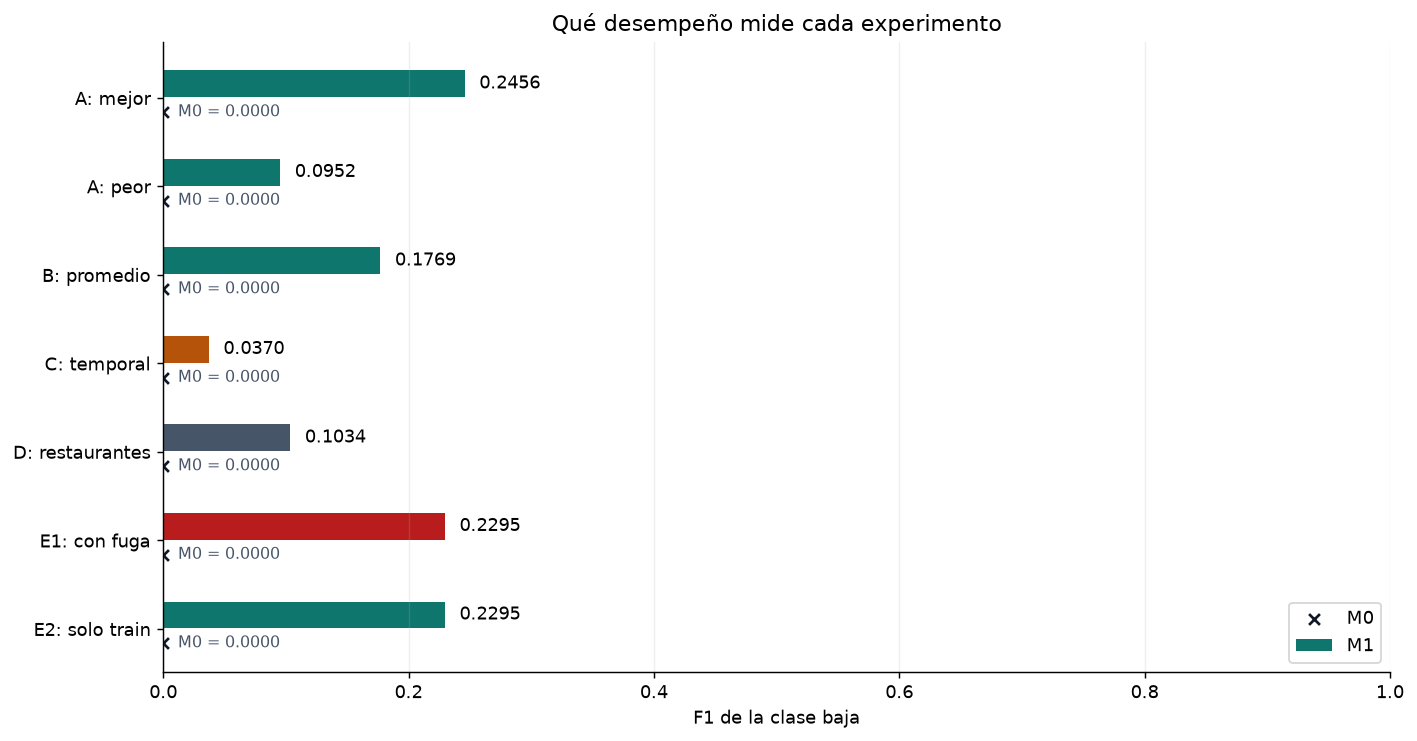

In [14]:
mejor_a = resultados_a.loc[resultados_a.f1.idxmax()]
peor_a = resultados_a.loc[resultados_a.f1.idxmin()]
comparativa = pd.DataFrame([
    {'Experimento': f'A: aleatorio, mejor semilla ({int(mejor_a.semilla)})',
     'F1 M1': mejor_a.f1, 'F1 M0': mejor_a.f1_baseline,
     'Situación real': 'Pedidos mezclados de negocios conocidos; resultado elegido por ser el mejor'},
    {'Experimento': f'A: aleatorio, peor semilla ({int(peor_a.semilla)})',
     'F1 M1': peor_a.f1, 'F1 M0': peor_a.f1_baseline,
     'Situación real': 'Misma población actual; muestra variación por partición'},
    {'Experimento': 'B: stratify, promedio de 5 semillas',
     'F1 M1': resultados_b.f1.mean(), 'F1 M0': resultados_b.f1_baseline.mean(),
     'Situación real': 'Comparar modelos con datos actuales y proporción de clases controlada'},
    {'Experimento': 'C: por fecha (julio-agosto)',
     'F1 M1': r_t['f1'], 'F1 M0': r_t['f1_baseline'],
     'Situación real': 'Entrenar con el pasado y predecir pedidos posteriores'},
    {'Experimento': 'D: por restaurante',
     'F1 M1': r_g['f1'], 'F1 M0': r_g['f1_baseline'],
     'Situación real': 'Pedidos de dos restaurantes no vistos en el entrenamiento'},
    {'Experimento': 'E: versión 1 (promedio con todo)',
     'F1 M1': r_e1['f1'], 'F1 M0': r_e1['f1_baseline'],
     'Situación real': 'Evaluación contaminada por respuestas del test; no reproduce producción'},
    {'Experimento': 'E: versión 2 (promedio con train)',
     'F1 M1': r_e2['f1'], 'F1 M0': r_e2['f1_baseline'],
     'Situación real': 'Negocios con historial en train; no valida por sí sola el futuro'},
])
display(comparativa)
comparativa.to_csv(SALIDA / 'tabla_comparativa.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 5.8))
etiquetas = ['A: mejor', 'A: peor', 'B: promedio', 'C: temporal',
             'D: restaurantes', 'E1: con fuga', 'E2: solo train']
y = np.arange(len(comparativa))
colores = ['#0f766e', '#0f766e', '#0f766e', '#b45309', '#475569', '#b91c1c', '#0f766e']
ax.barh(y - .16, comparativa['F1 M1'], height=.30, color=colores, label='M1')
ax.scatter(comparativa['F1 M0'], y + .16, marker='x', color='#111827', label='M0')
for i, fila in comparativa.iterrows():
    ax.text(fila['F1 M1'] + .012, i - .16, f"{fila['F1 M1']:.4f}", va='center')
    ax.text(.012, i + .16, f"M0 = {fila['F1 M0']:.4f}", va='center',
            color='#475569', fontsize=9)
ax.set(yticks=y, yticklabels=etiquetas, xlim=(0, 1),
       xlabel='F1 de la clase baja', title='Qué desempeño mide cada experimento')
ax.invert_yaxis()
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
fig.savefig(FIGURAS / '03_comparativa.png', bbox_inches='tight')
plt.show()

## 13. Para llevar a la clase
**Reflexión propuesta con apoyo de IA; revisar y discutir en el grupo.**

El hallazgo que más nos sorprendió fue que agregar un promedio de calificaciones
bajas calculado con toda la base no mejoró el F1 frente a calcularlo solo con
train: ambas versiones dieron **M1 = 0.2295; M0 = 0.0000**.
Nuestra hipótesis inicial era que la versión con información del test obtendría
un resultado mayor. El empate nos obliga a separar dos preguntas: si el número
subió y si el procedimiento es válido. La versión 1 sigue usando respuestas
que no existirían al recibir un pedido, aun cuando la métrica no muestre
una ventaja. No sería correcto cambiar las semillas para fabricar el resultado
que esperábamos.

También fue importante observar la fragilidad del reparto aleatorio. Con el
mismo modelo, A varió entre **M1 = 0.0952-0.2456;
M0 = 0.0000**, y el test pasó de 3 a 15 calificaciones bajas. Al reservar
los meses posteriores, el desempeño fue **M1 = 0.0370; M0 = 0.0000**,
con solo una baja detectada de catorce. Esto sugiere que elegir el resultado
más alto no ayuda a tomar una decisión realista.

**Pregunta que nos queda:** ¿se repetiría la caída temporal al evaluar varios
periodos posteriores, y cuánto se explica por los tipos de pedidos frente a
cambios en el servicio? El contraste entre julio y agosto invita a revisar
esa cuestión, pero una sola partición no permite responderla.

**Regla propuesta para Ruta Verde, en una frase y sin tecnicismos:**  
Antes de confiar en una predicción, probémosla con pedidos que se parezcan a
los que llegarán mañana y sin mirar sus respuestas.

## Comprobaciones y reproducibilidad
Los controles siguientes verifican condiciones que afectan la interpretación:
separación de filas, orden temporal, separación de grupos, mayoría de M0
e identidad de filas entre E1 y E2. No se seleccionan semillas para elevar
el resultado ni se cambia el umbral del clasificador.

In [15]:
datos_auditoria = {
    'filas': len(df), 'ids_unicos': int(df.pedido_id.nunique()),
    'restaurantes': int(df.restaurante.nunique()),
    'fecha_min': str(df.fecha.min().date()), 'fecha_max': str(df.fecha.max().date()),
    'tiempo_min': float(df.tiempo_entrega_min.min()),
    'tiempo_max': float(df.tiempo_entrega_min.max()),
    'nulos': {k: int(v) for k,v in df.isna().sum().items()},
    'duplicados': int(df.duplicated().sum()),
    'ids_repetidos': int(df.pedido_id.duplicated().sum()),
    'restaurantes_pedidos': {k: int(v) for k,v in df.restaurante.value_counts().items()},
    'n_cal': len(cal), 'n_reg': len(reg), 'positivos': int(cal.baja.sum()),
    'prevalencia': float(cal.baja.mean()),
    'tiempos_no_positivos': int((df.tiempo_entrega_min <= 0).sum()),
    'tiempos_ge_200': int((df.tiempo_entrega_min >= 200).sum()),
    'a': resultados_a.to_dict('records'), 'b': resultados_b.to_dict('records'),
    'temporal': r_t, 'grupos': r_g, 'e1': r_e1, 'e2': r_e2,
    'temporal_diagnostico': diagnostico_t,
    'n_train_t': len(train_t), 'prevalencia_train_t': float(train_t.baja.mean()),
    'prevalencia_test_t': float(test_t.baja.mean()),
    'restaurantes_test_g': sorted(test_g.restaurante.unique().tolist()),
    'n_train_g': len(train_g), 'prevalencia_train_g': float(train_g.baja.mean()),
    'prevalencia_test_g': float(test_g.baja.mean()),
    'categorias_nuevas_g': categorias_nuevas,
    'restaurantes_compartidos_a42': len(compartidos),
    'ids_compartidos_a42': len(ids_compartidos),
    'corr_positivos_f1_a': float(resultados_a.positivos_test.corr(resultados_a.f1)),
    'mensual': mensual.reset_index().assign(fecha=lambda x: x.fecha.astype(str)).to_dict('records'),
    'comparativa': comparativa.to_dict('records'),
    'sha256_csv': hashlib.sha256(RUTA_DATOS.read_bytes()).hexdigest(),
    'versiones': {p: version(p) for p in ['pandas', 'numpy', 'scikit-learn', 'matplotlib']},
    'python': platform.python_version(),
}
(SALIDA / 'resultados.json').write_text(json.dumps(datos_auditoria, ensure_ascii=False,
                                                 indent=2), encoding='utf-8')
pd.DataFrame(registros_splits).to_csv(SALIDA / 'particiones_auditables.csv', index=False)
print('Comprobaciones aprobadas: particiones, fecha, grupos y comparación E1/E2.')
print('SHA-256 del CSV:', datos_auditoria['sha256_csv'])
print('Versiones:', datos_auditoria['versiones'])
print('Python:', datos_auditoria['python'])

Comprobaciones aprobadas: particiones, fecha, grupos y comparación E1/E2.
SHA-256 del CSV: 9f5ffce2879a7634fe1dd01ac7c0e6c517036c6e17f01d4a23d661d3e41964c1
Versiones: {'pandas': '2.3.3', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
Python: 3.12.14


## Referencias y límites del análisis
- **Enunciado:** Laboratorio 9 - Estrategias de Partición de Datos,
  Ing. Max Cerna, Universidad Rafael Landívar, segundo semestre de 2026.
- **Datos:** pedidos_ruta_verde.csv proporcionado junto con los materiales locales.
- [scikit-learn: validación y estrategias de partición](https://scikit-learn.org/stable/modules/cross_validation.html).
- [scikit-learn: fuga de información y uso de Pipeline](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn: GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).
- [scikit-learn: TargetEncoder y codificación cruzada](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html).

Las cinco semillas no son cinco muestras independientes de un negocio nuevo.
Su dispersión es descriptiva, no un intervalo de confianza. Un solo corte
temporal y dos negocios reservados tampoco garantizan el resultado de
septiembre o de cualquier restaurante nuevo. Los nulos de calificación
pueden introducir un sesgo si los clientes que no califican son distintos.
Se conserva el CSV original para reproducir la guía; sus duplicados y
variantes de categorías requieren revisión antes de una aplicación real.